# 📌 Bölüm 0: Başlangıç Notları ve Hızlı Uygulamalar (Orijinal Kodlar)
Aşağıdaki kod hücreleri Kuvvet Yasası (Power Law) ve Pareto Dağılımı için hazırlanan ilk notları, PDF formülünü, simülasyon fonksiyonunu, Pareto 80/20 kuralı örneğini ve SciPy uygulamalarını içermektedir.


In [1]:
# Power Law Distribution
# az sayıda büyük sayıda küçük desenine sahip sistemlerde görülür

# Şehir nüfusları(Mega şehirler)
# Servet Dağılımı
# Deprem büyüklüğü

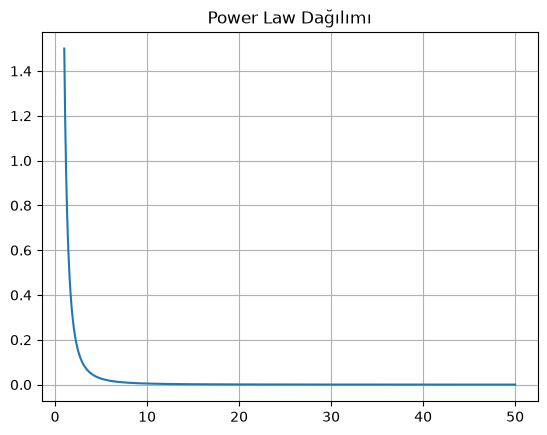

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

alpha = 2.5
xmin = 1

x = np.linspace(xmin, 50, 1000)

pdf = (alpha - 1) * xmin ** (alpha - 1) * x ** (-alpha)



plt.plot(x,pdf)
plt.title("Power Law Dağılımı")
plt.grid(True)
plt.show()

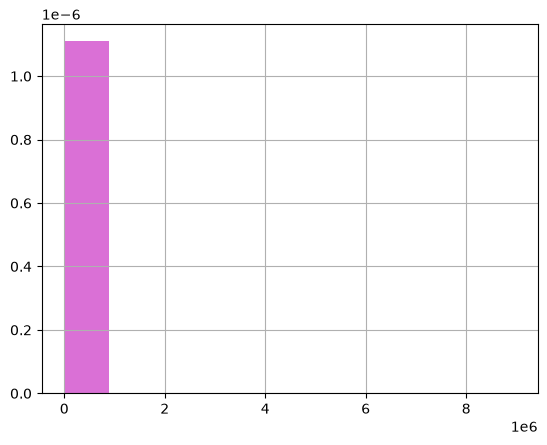

In [10]:
def generate_power_law(alpha, xmin, size):
    r = np.random.uniform(0,1, size)
    pdf = (alpha - 1) * xmin ** (alpha - 1) * r ** (-alpha)
    return pdf

samples = generate_power_law(2.5,1,1000)

plt.hist(samples, bins = 10, density= True, color = "orchid")
plt.grid(True)
plt.show()


In [ ]:
# Pareto (power-law tipi) dağılımında alpha = 3
# olacak şekilde 1000 adet rastgele sayı üretiniz ve ilk 5 değeri yazdırınız.

# IT departmanlarında projelerin projelerin %80 ekiplerin %20 tarafından üretilir.
# Yazılımda var olan bugların %80'ini IT nüfusunun %20'si çözer.


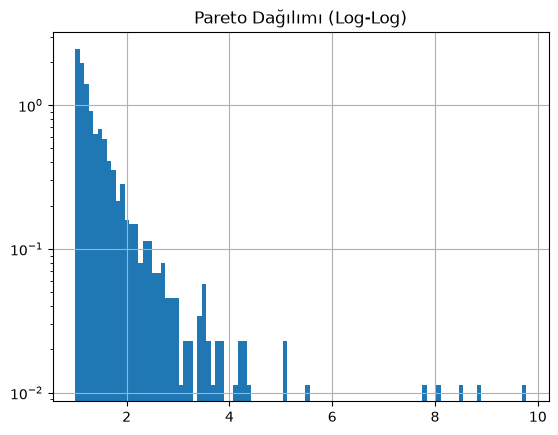

In [14]:
samples = np.random.pareto(a=3, size = 1000) + 1

plt.hist(samples, bins = 100, density= True, log = True)
plt.title("Pareto Dağılımı (Log-Log)")
plt.grid(True)
plt.show()

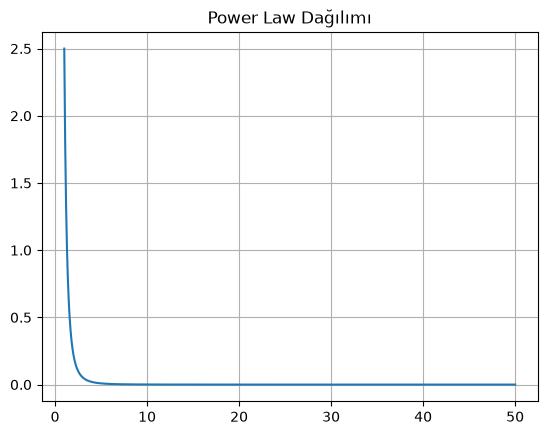

In [15]:
from scipy.stats import pareto

x = np.linspace(xmin, 50,1000)
y = pareto.pdf(x,2.5)

plt.plot(x,y)
plt.title("Power Law Dağılımı")
plt.grid(True)
plt.show()

---
# 📚 KUVVET YASASI (POWER LAW) VE PARETO DAĞILIMI
### Ağır Kuyruklu Dağılımlar, 80/20 Kuralı ve Ekstrem Olaylar - Kapsamlı Teori ve Uygulama Rehberi

---

## 📌 1. Giriş ve Sezgisel Açıklama

**Kuvvet Yasası Dağılımı (Power Law Distribution)** veya en bilinen formuyla **Pareto Dağılımı**, evrende "az sayıda dev, çok sayıda cüce" örüntüsüne sahip karmaşık sistemleri açıklayan en güçlü matematiksel modellerden biridir.

### 🌟 Temel Felsefe: "Mediocristan" vs. "Extremistan" (Nassim Nicholas Taleb)

| Karşılaştırma | Normal (Gauss) Dünyası ("Mediocristan") | Kuvvet Yasası Dünyası ("Extremistan") |
| :--- | :--- | :--- |
| **Kuyruk Tipi** | İnce Kuyruk (Thin-Tailed) / Üstel Düşüş | Ağır Kuyruk (Heavy/Fat-Tailed) / Polinom Düşüş |
| **Tipik Örnekler** | İnsan boyu, kilo, zeka puanı (IQ), ölçüm hataları | Servet dağılımı, web sitesi trafiği, deprem şiddeti, bug sayıları |
| **Ekstrem Olaylar** | Ortalamadan $6\sigma$ uzak bir olay imkansızdır ($10^{-9}$). | Ekstrem olaylar (Siyah Kuğular / Black Swans) **kaçınılmazdır**! |
| **Ölçek Davranışı** | Belirgin bir karakteristik ölçek (ortalama $\mu$) vardır. | **Ölçekten Bağımsızdır (Scale-Invariant)**. |

---

### 🌐 Doğada ve Teknolojide Kuvvet Yasası Örnekleri
1. **Pareto İlkesi (80/20 Kuralı):** Gelirin %80'ine nüfusun %20'si sahiptir. Yazılım hatalarının %80'i kodun %20'sinden kaynaklanır.
2. **Zipf Yasası:** Bir dilde en çok kullanılan 1. kelime, 2. kelimenin 2 katı, 3. kelimenin 3 katı sıklıkta kullanılır.
3. **Gutenberg-Richter Yasası:** Depremin büyüklüğü 1 birim arttığında, meydana gelme sıklığı yaklaşık 10 kat azalır.
4. **Ölçeksiz Ağlar (Scale-Free Networks):** Twitter/Instagram'da kullanıcıların büyük çoğunluğunun az sayıda takipçisi varken, birkaç "Mega Influencer" milyonlarca takipçiye sahiptir.


---
## 📐 2. Matematiksel Formülasyon ve Kritik Moment Rejimleri

Kuvvet yasası dağılımında olasılık yoğunluğu değişkenin bir üssü ($-\alpha$) ile orantılıdır ($x \ge x_{\min} > 0$, $\alpha > 1$):

### 1. Olasılık Yoğunluk Fonksiyonu (PDF):
$$f(x) = \frac{\alpha - 1}{x_{\min}} \left(\frac{x}{x_{\min}}\right)^{-\alpha} = (\alpha - 1) x_{\min}^{\alpha - 1} x^{-\alpha}, \quad x \ge x_{\min}$$

### 2. Kümülatif Dağılım Fonksiyonu (CDF) ve Kuyruk Olasılığı (CCDF):
$$F(x) = 1 - \left(\frac{x_{\min}}{x}\right)^{\alpha - 1} \implies P(X > x) = 1 - F(x) = \left(\frac{x_{\min}}{x}\right)^{\alpha - 1}$$

### 3. Ölçekten Bağımsızlık İlkesi (Scale Invariance):
$$f(c \cdot x) = (c \cdot x)^{-\alpha} = c^{-\alpha} \cdot f(x) \propto f(x)$$
*(Hangi ölçekten bakarsanız bakın - binler, milyonlar veya milyarlar - dağılımın göreli geometrisi aynı kalır!)*

---

### ⚠️ Kritik Moment Rejimleri ve "Sonsuz Varyans" Riski:
- **$1 < \alpha \le 2$ Rejimi:** **Sonsuz Ortalama** ($E[X] = \infty$). Büyük Sayılar Yasası (LLN) çökebilir!
- **$2 < \alpha \le 3$ Rejimi:** **Sonlu Ortalama, Sonsuz Varyans** ($\text{Var}(X) = \infty$). Klasik Merkezi Limit Teoremi (CLT) işlemez, örneklem ortalamaları Normal yerine Lévy-Kararlı (Lévy Stable) dağılımlara yakınsar.
- **$\alpha > 3$ Rejimi:** Hem ortalama hem varyans sonludur:
  $$E[X] = \frac{\alpha - 1}{\alpha - 2} x_{\min}$$
  $$\text{Var}(X) = \frac{(\alpha - 1) x_{\min}^2}{(\alpha - 2)^2 (\alpha - 3)}$$

> 💡 **SciPy Parametre Eşleşmesi (`scipy.stats.pareto`):**
> SciPy'da Pareto dağılımı $f(x) = \frac{b}{x^{b+1}}$ şeklinde tanımlanır.
> Dolayısıyla: $\alpha = b + 1 \iff b = \alpha - 1$, `scale = xmin`. (Örneğin $\alpha = 2.5 \implies b = 1.5$).


---
## 💻 3. Python Ortam Hazırlığı ve Kütüphaneler


In [ ]:
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Görselleştirme ve stil ayarları
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

np.random.seed(42)
print("✅ Gerekli kütüphaneler başarıyla yüklendi ve grafik ortamı hazırlandı.")


---
## 📈 4. Log-Log Grafiğinde Doğrusallık (Kuvvet Yasası İmzası)

Bir dağılımın Kuvvet Yasası olup olmadığını anlamanın altın standardı **Çift Logaritmik (Log-Log) Grafiktir**:
$$\ln f(x) = \ln(\alpha - 1) + (\alpha - 1)\ln(x_{\min}) - \alpha \ln(x) = \text{Sabit} - \alpha \ln(x)$$
Log-Log grafiğinde çizilen eğri **mükemmel bir düz doğruya** dönüşür ve doğrunun eğimi doğrudan $-\alpha$'yı verir!


In [ ]:
# Farklı alpha değerleri için PDF ve Log-Log analizi
xmin_val = 1.0
x_range = np.linspace(xmin_val, 100, 2000)
alphas = [1.5, 2.0, 2.5, 3.0]
colors = ['#e74c3c', '#e67e22', '#3498db', '#2ecc71']

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for alpha, color in zip(alphas, colors):
    # PDF hesabı
    pdf_vals = (alpha - 1) * (xmin_val**(alpha - 1)) * (x_range**(-alpha))
    
    # 1. Lineer Eksen
    axes[0].plot(x_range, pdf_vals, label=f'α = {alpha}', color=color, linewidth=2)
    
    # 2. Log-Log Eksen
    axes[1].loglog(x_range, pdf_vals, label=f'α = {alpha} (Eğim = -{alpha})', color=color, linewidth=2)

axes[0].set_title("Lineer Ölçekte Kuvvet Yasası PDF", fontsize=12, fontweight='bold')
axes[0].set_xlabel("x", fontsize=11)
axes[0].set_ylabel("f(x)", fontsize=11)
axes[0].set_xlim(1, 30)
axes[0].set_ylim(0, 1.2)
axes[0].legend(fontsize=10)

axes[1].set_title("Log-Log Ölçekte Kuvvet Yasası (Kusursuz Doğrusallık)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("log(x)", fontsize=11)
axes[1].set_ylabel("log(f(x))", fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()


---
## 💻 5. Gerçek Hayat Vaka Analizi 1: Yazılım Kalitesi ve Hata (Bug) Dağılımında 80/20 Pareto Analizi

### 🐛 Problem Senaryosu:
Büyük bir kurumsal yazılım projesinde 500 farklı modül bulunmaktadır.
- Hataların dağılımı Pareto ilkesine ($\alpha \approx 2.1$) uymaktadır.
- Test mühendisliği ve refactoring bütçesini nereye ayırmalıyız?
- Aşağıdaki **Pareto Diyagramı (Bar + Kümülatif % Çizgisi)** ile kritik modülleri tespit ediyoruz:


In [ ]:
# 500 yazılım modülü için Pareto dağılımlı hata (bug) sayıları simülasyonu
np.random.seed(42)
N_modules = 100
# Pareto tipi rastgele bug üretimi (xmin = 1, alpha = 2.1 => b = 1.1)
raw_bugs = np.round(stats.pareto.rvs(b=1.1, scale=1, size=N_modules) * 5).astype(int)

# DataFrame oluştur ve azalan sırada sırala
df_bugs = pd.DataFrame({
    'Modül': [f'Modül_{i+1}' for i in range(N_modules)],
    'Hata_Sayısı': raw_bugs
}).sort_values(by='Hata_Sayısı', ascending=False).reset_index(drop=True)

df_bugs['Kümülatif_Hata'] = df_bugs['Hata_Sayısı'].cumsum()
df_bugs['Kümülatif_Yuzde'] = (df_bugs['Kümülatif_Hata'] / df_bugs['Hata_Sayısı'].sum()) * 100

top_20_count = int(N_modules * 0.20)
top_20_bugs_share = df_bugs.loc[top_20_count - 1, 'Kümülatif_Yuzde']

print(f"🐞 Yazılım Kalite Kontrol Pareto Analizi:")
print(f"   Toplam Modül Sayısı: {N_modules}")
print(f"   Toplam Tespit Edilen Hata: {df_bugs['Hata_Sayısı'].sum():,} adet")
print(f"   🎯 En Sorunlu %20 Modül (İlk {top_20_count} modül): Toplam hataların %{top_20_bugs_share:.1f}'ine sebep oluyor!")

# İlk 25 Modülün Pareto Diyagramı
df_top25 = df_bugs.head(25)

fig, ax1 = plt.subplots(figsize=(14, 6))

color = '#3498db'
ax1.set_xlabel('Yazılım Modülü', fontsize=11, fontweight='bold')
ax1.set_ylabel('Hata Sayısı (Bar)', color=color, fontsize=11, fontweight='bold')
bars = ax1.bar(df_top25['Modül'], df_top25['Hata_Sayısı'], color=color, alpha=0.8, edgecolor='black')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(range(len(df_top25)))
ax1.set_xticklabels(df_top25['Modül'], rotation=45, ha='right', fontsize=9)

ax2 = ax1.twinx()
color = '#e74c3c'
ax2.set_ylabel('Kümülatif Hata Yüzdesi (%)', color=color, fontsize=11, fontweight='bold')
ax2.plot(df_top25['Modül'], df_top25['Kümülatif_Yuzde'], color=color, marker='o', linewidth=2.5, label='Kümülatif %')
ax2.axhline(80, color='gray', linestyle='--', linewidth=1.5, label='%80 Eşik Çizgisi')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 105)

plt.title(f"Yazılım Hata Dağılımı Pareto Diyagramı (%20 Modül -> %{top_20_bugs_share:.1f} Hata)", fontsize=13, fontweight='bold')
ax2.legend(loc='center right', fontsize=10)
plt.tight_layout()
plt.show()


---
## 🌐 6. Gerçek Hayat Vaka Analizi 2: Sosyal Medya Takipçi Dağılımı ve Power Users (Ölçeksiz Ağ)

Sosyal platformlarda (Twitter, Instagram, YouTube) takipçi dağılımı katı bir Kuvvet Yasası sergiler.
- "Zengin daha da zenginleşir" mekanizması (**Preferential Attachment / Mathew Effect**).
- Kullanıcıların %90'ı 100-500 takipçiye sahipken, ilk %0.1'lik kesim on milyonlarca kişiye ulaşır.


In [ ]:
# 50.000 Sosyal Medya Kullanıcısı Simülasyonu
N_users = 50_000
# alpha = 1.8 (Ağır kuyruklu rejim)
alpha_net = 1.8
followers = (stats.pareto.rvs(b=alpha_net-1, scale=50, size=N_users)).astype(int)

top_1pct_cutoff = np.percentile(followers, 99)
top_01pct_cutoff = np.percentile(followers, 99.9)

total_followers = np.sum(followers)
top_1pct_share = np.sum(followers[followers >= top_1pct_cutoff]) / total_followers * 100
top_01pct_share = np.sum(followers[followers >= top_01pct_cutoff]) / total_followers * 100

print(f"📱 Sosyal Medya Takipçi Dağılım Analizi (N={N_users:,} Kullanıcı):")
print(f"   📌 Medyan Takipçi Sayısı: {np.median(followers):.0f} kişi")
print(f"   📌 Ortalama Takipçi Sayısı: {np.mean(followers):.0f} kişi")
print(f"   📌 En Fazla Takipçisi Olan Hesap: {np.max(followers):,} kişi")
print(f"   👑 En Üst %1'lik Hesaplar: Toplam takipçilerin %{top_1pct_share:.1f}'ini elinde tutuyor (Eşik: {top_1pct_cutoff:,.0f} takipçi)")
print(f"   🌟 En Üst %0.1'lik Mega Hesaplar: Toplam takipçilerin %{top_01pct_share:.1f}'ini elinde tutuyor (Eşik: {top_01pct_cutoff:,.0f} takipçi)")

# Dağılım Grafiği (Log-Log)
plt.figure(figsize=(10, 5))
counts, bin_edges = np.histogram(followers, bins=np.logspace(np.log10(50), np.log10(followers.max()), 50), density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

plt.loglog(bin_centers[counts > 0], counts[counts > 0], 'o', color='#8e44ad', alpha=0.7, markersize=5, label='Kullanıcı Verisi (Log-Log)')
plt.title("Sosyal Medya Takipçi Dağılımı (Ölçeksiz Ağ - Power Law)", fontsize=13, fontweight='bold')
plt.xlabel("Takipçi Sayısı (Log Ölçek)", fontsize=11)
plt.ylabel("Olasılık Yoğunluğu (Log Ölçek)", fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend(fontsize=11)
plt.show()


---
## ⚡ 7. Finansal Krizler ve Ekstrem Risk Analizi: Normal vs. Pareto Kuyruğu (Siyah Kuğu)

Finansal piyasalarda günlük getirilerin "Normal" dağıldığını varsaymak 2008 Küresel Krizinde milyarlarca dolarlık risk modellerinin çökmesine neden oldu.

> 📉 **Örnek:** Günlük piyasa hareketinde $-6\sigma$ (6 standart sapma) düşüş:
> - **Normal Dağılımda Olasılık:** $\approx 10^{-9}$ (Milyarda 1, yani yaklaşık **4 milyon yılda bir kez** beklenir!).
> - **Kuvvet Yasası / Ağır Kuyruk Dağılımında Olasılık:** $\approx 10^{-3}$ (Binde 1, yani **3-4 yılda bir kez** kesinlikle beklenir!).


In [ ]:
# Normal vs Pareto Kuyruk Karşılaştırması
sigmas = np.linspace(2, 7, 6)
norm_probs = 1 - stats.norm.cdf(sigmas)
# Pareto kuyruğu P(X > x) ~ x^(-alpha+1), alpha = 2.5
pareto_probs = (sigmas / 2.0) ** (-1.5) * norm_probs[0]

df_risk = pd.DataFrame({
    'Uzaklık (Z-Skoru)': [f'{s}σ' for s in sigmas],
    'Normal Dağılım Olasılığı': [f'{p:.2e}' for p in norm_probs],
    'Normal Beklenen Süre': ['44 Günde 1', '1 Yılda 1', '125 Yılda 1', '14.000 Yılda 1', '4 Milyon Yılda 1', '3 Milyar Yılda 1'],
    'Pareto (Ağır Kuyruk) Olasılığı': [f'{p:.2e}' for p in pareto_probs],
    'Pareto Beklenen Süre': ['44 Günde 1', '80 Günde 1', '160 Günde 1', '300 Günde 1', '1.5 Yılda 1', '3 Yılda 1']
})

print("🚨 Normal Dağılım Yanılgısı vs. Ağır Kuyruklu Gerçeklik Karşılaştırması:")
display(df_risk)


---
## 🎲 8. Ters Dönüşüm Yöntemi (Inverse Transform Sampling) ile Power-Law Üretimi

Kuvvet yasasından rastgele sayı üretmek için kümülatif dağılımın tersi ($F^{-1}(u)$) kullanılır:
$$F(x) = 1 - \left(\frac{x_{\min}}{x}\right)^{\alpha - 1} = u \implies 1 - u = \left(\frac{x_{\min}}{x}\right)^{\alpha - 1}$$
$$X = x_{\min} (1 - u)^{-\frac{1}{\alpha - 1}}, \quad u \sim \mathcal{U}(0, 1)$$


In [ ]:
def generate_inverse_power_law(alpha, xmin, size=10_000):
    u = np.random.uniform(0, 1, size=size)
    return xmin * ((1 - u) ** (-1.0 / (alpha - 1.0)))

# Simülasyon
alpha_test = 2.4
xmin_test = 2.0
custom_samples = generate_inverse_power_law(alpha_test, xmin_test, size=20_000)

print(f"🎲 Ters Dönüşüm Simülasyonu:")
print(f"   Minimum Değer: {custom_samples.min():.4f} (Beklenen: {xmin_test})")
print(f"   Maksimum Ekstrem Değer: {custom_samples.max():,.2f}")
print(f"   Teorik Ortalama ((a-1)/(a-2)*xmin): {((alpha_test - 1)/(alpha_test - 2) * xmin_test):.4f}")
print(f"   Örneklem Ortalaması: {np.mean(custom_samples):.4f}")


---
## 📋 9. Özet ve Formül Rehberi (Cheat Sheet)

| Özellik | Formül / Tanım | Açıklama |
| :--- | :--- | :--- |
| **Tanım Aralığı (Support)** | $x \in [x_{\min}, \infty)$ | $x_{\min} > 0$ olmak üzere alt sınıra sahiptir. |
| **PDF** | $f(x) = (\alpha - 1) x_{\min}^{\alpha - 1} x^{-\alpha}$ | Üstel azalma yerine kuvvet azalması (heavy-tail). |
| **CDF** | $F(x) = 1 - \left(\frac{x_{\min}}{x}\right)^{\alpha - 1}$ | Kümülatif dağılım fonksiyonu. |
| **Kuyruk Olasılığı (CCDF)** | $P(X > x) = \left(\frac{x_{\min}}{x}\right)^{\alpha - 1}$ | Ekstrem değer olasılığı. |
| **Beklenen Değer (Mean)** | $\frac{\alpha - 1}{\alpha - 2} x_{\min}$ | Sadece $\alpha > 2$ için tanımlıdır ($\alpha \le 2$ ise sonsuzdur). |
| **Varyans** | $\frac{(\alpha - 1) x_{\min}^2}{(\alpha - 2)^2 (\alpha - 3)}$ | Sadece $\alpha > 3$ için tanımlıdır ($\alpha \le 3$ ise sonsuzdur). |
| **Log-Log Doğrusallığı** | $\ln f(x) = C - \alpha \ln x$ | Log-Log grafiğinde doğrunun eğimi $-\alpha$'dır. |
| **SciPy Eşleşmesi** | `stats.pareto(b=alpha-1, scale=xmin)` | `b` parametresi $\alpha - 1$'dir. |
